# Model B - Lightweight depthwise separable CNN (EuroSAT)

Replace all four standard convolutions in `ModelA.ipynb` with **SeparableConv2D**:
3x3 depthwise convolution followed by 1x1 pointwise convolution. Retain Model A's
32 -> 64 -> 128 -> 256 filters, BatchNorm, ReLU, max-pooling and dense classifier.

**80,293 trainable parameters**, below the 100,000 limit; **81,253 total parameters**
and **7,345,408 convolution/dense MACs per image**.

Run from the repository directory. Reuse existing images or an official local ZIP;
download only when necessary. All generated dataset files stay under `data/`, covered
by the existing `.gitignore`. The committed `data/eurosat_split.csv` preserves Model A's
exact 70/15/15 split. No augmentation is applied.

This notebook includes architecture analysis, 20-epoch training, validation curves,
held-out test evaluation and saved results. Accuracy is measured when you run it.
Optimizer comparisons against SGD and SGD with momentum remain separate assignment work.

In [45]:
import hashlib
import json
import http.client
import re
import time
import urllib.error
import shutil
import urllib.request
import zipfile
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)

PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = PROJECT_DIR / 'data' / 'eurosat' / 'EuroSAT_RGB'
DATA_ARCHIVE = None  # Optional path to an already downloaded official ZIP.
DOWNLOAD_DATASET = True  # Used only when no complete extracted dataset is found.
DATASET_URL = 'https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1'
DATASET_MD5 = 'f46e308c4d50d4bf32fedad2d3d62f3b'

SPLIT_CSV = PROJECT_DIR / 'data' / 'eurosat_split.csv'
RESULTS_DIR = PROJECT_DIR / 'results'
FIGURES_DIR = PROJECT_DIR / 'figures'
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
IMG_SIZE = (64, 64)
SEED = 42
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
PARAMETER_LIMIT = 100_000

tf.keras.utils.set_random_seed(SEED)
print('Project:', PROJECT_DIR)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU') or 'none')

Project: C:\Users\rashmika\Desktop\CNN-For-Image-Classification
TensorFlow 2.21.0 | GPU: none


## 1. Find or download the dataset

Reuse complete images under `DATA_DIR` (including nested archive layouts), or prepared
`data/eurosat/train|val|test` folders from `Dataset.ipynb`. Otherwise use `DATA_ARCHIVE`
or `data/EuroSAT_RGB.zip`. If neither exists and `DOWNLOAD_DATASET=True`, download
the official ZIP (~95 MB). Verify its MD5 before extraction.

Partial downloads use `DATA_DIR/EuroSAT_RGB.zip.part`; verified archives move to
`data/EuroSAT_RGB.zip`. Extract only expected images into `DATA_DIR/<class>/<file>`.
These paths are covered by `data/*.zip` and `data/eurosat/` in `.gitignore`.
Extracted images are checked for completeness against the shared split manifest;
the original archive checksum does not authenticate existing extracted files.

Downloads use 4 MiB HTTP ranges, show progress, and retry interrupted transfers up
to five times per range. Existing `.part` data is resumed rather than overwritten
when the server supports byte ranges. A complete archive must pass the official MD5
check before it is moved or extracted. If retries are exhausted, rerun the cell to
resume the saved partial download.


In [46]:
def read_split_manifest(path):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}. Run from the repository with its committed split CSV.')
    frame = pd.read_csv(path, dtype=str)
    required = ['file', 'label', 'split']
    if not set(required).issubset(frame.columns) or frame[required].isna().any().any():
        raise ValueError('Split CSV requires nonempty file, label and split columns.')
    if frame.duplicated(['label', 'file']).any():
        raise ValueError('An image occurs more than once in the split manifest.')
    for column in ['file', 'label']:
        if frame[column].map(lambda v: '/' in v or chr(92) in v or v in {'.', '..'}).any():
            raise ValueError(f'Invalid path component in {column}.')
    if frame.groupby('split').size().to_dict() != {'train': 18900, 'val': 4050, 'test': 4050}:
        raise ValueError('Expected the shared EuroSAT 27,000-image 70/15/15 split.')
    if frame.label.nunique() != 10:
        raise ValueError('Expected 10 classes.')
    return frame


def index_extracted_images(root, expected_keys):
    index = {}
    if root.is_dir():
        for path in sorted(root.rglob('*.jpg')):
            key = (path.parent.name, path.name)
            if key in expected_keys:
                if key in index:
                    raise ValueError(f'Duplicate image {key} under {root}; choose one dataset root.')
                index[key] = path
    return index


def verify_archive(path):
    digest = hashlib.md5()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    if digest.hexdigest() != DATASET_MD5:
        raise ValueError(f'MD5 mismatch for {path} ({path.stat().st_size:,} bytes): '
                         f'expected {DATASET_MD5}, got {digest.hexdigest()}. '
                         'The file is incomplete or corrupted; it will not be extracted.')



def download_archive(archive, max_attempts=5, chunk_size=4 * 1024 * 1024):
    """Resume bounded HTTP ranges; promote only an MD5-verified complete ZIP."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive.parent.mkdir(parents=True, exist_ok=True)
    partial = DATA_DIR / 'EuroSAT_RGB.zip.part'
    if partial.is_file() and zipfile.is_zipfile(partial):
        try:
            verify_archive(partial)
        except ValueError:
            print('Discarding a complete partial archive with an invalid checksum.')
            partial.write_bytes(b'')
        else:
            partial.replace(archive)
            print('Using completed, verified download:', archive)
            return

    total = None
    print('Downloading/resuming', DATASET_URL, flush=True)
    while total is None or partial.stat().st_size < total:
        for attempt in range(1, max_attempts + 1):
            offset = partial.stat().st_size if partial.exists() else 0
            headers = {
                'User-Agent': 'EuroSAT-assignment/1.0',
                'Range': f'bytes={offset}-{offset + chunk_size - 1}',
                'Accept-Encoding': 'identity',
                'Cache-Control': 'no-cache',
            }
            try:
                request = urllib.request.Request(DATASET_URL, headers=headers)
                with urllib.request.urlopen(request, timeout=120) as response:
                    if response.status == 206:
                        match = re.fullmatch(r'bytes ([0-9]+)-([0-9]+)/([0-9]+)',
                                             response.headers.get('Content-Range', ''))
                        if match is None:
                            raise ValueError('Server returned an invalid Content-Range.')
                        start, end, remote_total = map(int, match.groups())
                        if start != offset or end < start or end >= remote_total:
                            raise ValueError('Server returned the wrong byte range.')
                        if total is not None and remote_total != total:
                            raise ValueError('Archive size changed during download.')
                        total = remote_total
                        remaining = end - start + 1
                        with partial.open('ab') as target:
                            while remaining:
                                block = response.read(min(64 * 1024, remaining))
                                if not block:
                                    raise OSError(f'Connection closed with {remaining:,} range bytes missing.')
                                target.write(block)
                                remaining -= len(block)
                    elif response.status == 200:
                        # Servers that ignore Range must restart, never append a full response.
                        length = response.headers.get('Content-Length')
                        total = int(length) if length is not None else None
                        with partial.open('wb') as target:
                            while True:
                                block = response.read(64 * 1024)
                                if not block:
                                    break
                                target.write(block)
                        if total is None:
                            total = partial.stat().st_size
                        if partial.stat().st_size != total:
                            raise OSError(f'Incomplete response: {partial.stat().st_size:,} of {total:,} bytes.')
                    else:
                        raise OSError(f'Unexpected HTTP status {response.status}.')
                downloaded = partial.stat().st_size
                print(f'Downloaded {downloaded / 1e6:.1f} / {total / 1e6:.1f} MB '
                      f'({downloaded / total:.0%})', flush=True)
                break
            except (OSError, http.client.HTTPException, ValueError) as error:
                if attempt == max_attempts:
                    raise RuntimeError(
                        f'Download interrupted after {max_attempts} attempts. '
                        f'Partial data is kept at {partial}; rerun this cell to resume. '
                        f'Last error: {error}'
                    ) from error
                delay = min(2 ** (attempt - 1), 8)
                print(f'Download interrupted: {error}. Retrying in {delay}s...', flush=True)
                time.sleep(delay)

    verify_archive(partial)
    partial.replace(archive)
    print('Download complete; official MD5 verified:', archive)


def ensure_dataset(expected_keys):
    for root in [DATA_DIR, PROJECT_DIR / 'data' / 'eurosat']:
        index = index_extracted_images(root, expected_keys)
        if expected_keys.issubset(index):
            print('Using extracted images:', root)
            return index

    if DATA_ARCHIVE is not None:
        archive = Path(DATA_ARCHIVE).expanduser()
        if not archive.is_absolute():
            archive = PROJECT_DIR / archive
        if not archive.is_file():
            raise FileNotFoundError(f'Configured DATA_ARCHIVE does not exist: {archive}')
    else:
        archive = PROJECT_DIR / 'data' / 'EuroSAT_RGB.zip'
        if not archive.is_file():
            archive = None

    if archive is None:
        if not DOWNLOAD_DATASET:
            raise FileNotFoundError('No complete dataset or ZIP. Set DATA_ARCHIVE or DOWNLOAD_DATASET=True.')
        archive = PROJECT_DIR / 'data' / 'EuroSAT_RGB.zip'
        download_archive(archive)
    else:
        verify_archive(archive)

    with zipfile.ZipFile(archive) as source:
        members = {}
        for member in source.infolist():
            path = PurePosixPath(member.filename)
            key = (path.parent.name, path.name)
            if not member.is_dir() and key in expected_keys:
                if key in members:
                    raise ValueError(f'Duplicate image {key} in the archive.')
                members[key] = member
        if not expected_keys.issubset(members):
            raise ValueError('ZIP is missing images required by the shared split.')
        # Destination components come from the validated manifest, not archive paths.
        for (label, filename), member in members.items():
            target = DATA_DIR / label / filename
            target.parent.mkdir(parents=True, exist_ok=True)
            with source.open(member) as image, target.open('wb') as output:
                shutil.copyfileobj(image, output)
    index = index_extracted_images(DATA_DIR, expected_keys)
    if not expected_keys.issubset(index):
        raise ValueError('Dataset extraction is incomplete.')
    print('Extracted verified archive to:', DATA_DIR)
    return index


split = read_split_manifest(SPLIT_CSV)
expected_keys = set(zip(split.label, split.file))
image_index = ensure_dataset(expected_keys)
split['path'] = [str(image_index[(row.label, row.file)]) for row in split.itertuples()]
CLASS_NAMES = sorted(split.label.unique())
NUM_CLASSES = len(CLASS_NAMES)
print(NUM_CLASSES, 'classes:', CLASS_NAMES)
print(pd.crosstab(split.label, split.split)[['train', 'val', 'test']])

Using extracted images: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\data\eurosat\EuroSAT_RGB
10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
split                 train  val  test
label                                 
AnnualCrop             2100  450   450
Forest                 2100  450   450
HerbaceousVegetation   2100  450   450
Highway                1750  375   375
Industrial             1750  375   375
Pasture                1400  300   300
PermanentCrop          1750  375   375
Residential            2100  450   450
River                  1750  375   375
SeaLake                2100  450   450


In [47]:
def decode_image(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.ensure_shape(image, IMG_SIZE + (3,))
    return tf.image.convert_image_dtype(image, tf.float32), label


def load_split(name, shuffle):
    frame = split.loc[split.split == name].sort_values(['label', 'file'])
    labels = frame.label.map({label: i for i, label in enumerate(CLASS_NAMES)}).to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(dtype=str), labels))
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    # Shuffle paths before decoding to keep the buffer small.
    dataset = dataset.map(decode_image, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH).prefetch(AUTOTUNE)


train_ds = load_split('train', shuffle=True)
val_ds = load_split('val', shuffle=False)
test_ds = load_split('test', shuffle=False)
print('Images:', split.groupby('split').size().to_dict())

Images: {'test': 4050, 'train': 18900, 'val': 4050}


## 2. Architecture

Four **SeparableConv2D (3x3 depthwise + 1x1 pointwise, no bias, depth multiplier 1)
-> BatchNorm -> ReLU -> MaxPool (2x2)** blocks, followed by the same head as Model A.

| Stage | Output after pooling | Convolution weights | BatchNorm trainable |
|---|---|---:|---:|
| 3 -> 32 | 32x32x32 | 9x3 + 3x32 = 123 | 64 |
| 32 -> 64 | 16x16x64 | 9x32 + 32x64 = 2,336 | 128 |
| 64 -> 128 | 8x8x128 | 9x64 + 64x128 = 8,768 | 256 |
| 128 -> 256 | 4x4x256 | 9x128 + 128x256 = 33,920 | 512 |
| Global average pooling | 256 | 0 | 0 |
| Dense(128, ReLU), Dropout(0.5) | 128 | 256x128 + 128 = 32,896 | 0 |
| Dense(10, softmax) | 10 | 128x10 + 10 = 1,290 | 0 |

Trainable: 45,147 convolution + 960 BatchNorm + 34,186 dense = **80,293**.
BatchNorm also has 960 non-trainable statistics, giving **81,253 total**.
The 100,000 limit applies to all trainable weights in the whole model.

In [48]:
def build_model_b(input_shape=IMG_SIZE + (3,), num_classes=NUM_CLASSES):
    """Model B - depthwise separable CNN. Calling it again gives a model with fresh weights."""
    inputs = layers.Input(shape=input_shape)
    x = inputs
    for filters in [32, 64, 128, 256]:
        x = layers.SeparableConv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs, name="Model_B_DepthwiseSeparableCNN")

model_b = build_model_b()
model_b.summary()
n_trainable = int(sum(np.prod(w.shape) for w in model_b.trainable_weights))
assert n_trainable <= PARAMETER_LIMIT

Model: "Model_B_DepthwiseSeparableCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_36             │ (None, 64, 64, 32)     │           123 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_36 (ReLU)                 │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_37             │ (None, 32, 32, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_37 (ReLU)                 │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_38             │ (None, 16, 16, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_38 (ReLU)                 │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_39             │ (None, 8, 8, 256)      │        33,920 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_39 (ReLU)                 │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 81,253 (317.39 KB)

 Trainable params: 80,293 (313.64 KB)

 Non-trainable params: 960 (3.75 KB)

In [49]:
# Check: a batch of 64x64x3 images gives one probability vector of length 10 per image
x_batch, y_batch = next(iter(val_ds))
probs = model_b.predict(x_batch, verbose=0)
n_trainable = int(sum(np.prod(w.shape) for w in model_b.trainable_weights))
print("pixel range       :", float(x_batch.numpy().min()), "to", float(x_batch.numpy().max()))
print("input  shape      :", x_batch.shape)
print("output shape      :", probs.shape)
print("rows sum to 1     :", bool(np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)))
print("total params      :", f"{model_b.count_params():,}")
print("trainable params  :", f"{n_trainable:,}")
assert probs.shape == (len(x_batch), NUM_CLASSES)
assert np.isfinite(probs).all()
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)
assert n_trainable <= PARAMETER_LIMIT

pixel range       : 0.09803922474384308 to 1.0
input  shape      : (32, 64, 64, 3)
output shape      : (32, 10)
rows sum to 1     : True
total params      : 81,253
trainable params  : 80,293


## 3. Parameters and MACs per layer

For depth multiplier 1 and no convolution bias:

| Operation | Parameters | MACs per image |
|---|---|---|
| Standard convolution | k x k x Cin x Cout | H x W x k x k x Cin x Cout |
| Depthwise part | k x k x Cin | H x W x k x k x Cin |
| Pointwise part | Cin x Cout | H x W x Cin x Cout |
| BatchNorm | 4C total; 2C trainable | excluded assuming inference folding |
| Dense | Nin x Nout + Nout | Nin x Nout |

Use Model A's convention: convolution/dense MACs, excluding pooling comparisons,
GAP additions, ReLU, biases and softmax. These are estimates, not measured latency
or every instruction. A deployment optimizer can fold BatchNorm into the pointwise
convolution; this notebook does not perform folding.

In [50]:
def layer_table(model):
    """One row per layer that has weights; parameters from the formulas above."""
    rows = []
    for layer in model.layers:
        if isinstance(layer, layers.SeparableConv2D):
            h, w, c_out = layer.output.shape[1:]
            c_in = layer.input.shape[-1]
            k = layer.kernel_size[0]
            expanded = c_in * layer.depth_multiplier
            weights = k * k * expanded + expanded * c_out
            p = weights + (c_out if layer.use_bias else 0)
            rows.append(dict(layer=f"SeparableConv2D {c_in}->{c_out}", kernel=f"{k}x{k} + 1x1", filters_units=c_out,
                             output=f"{h}x{w}x{c_out}", params=p, trainable=p, macs=h * w * weights))
        elif isinstance(layer, layers.BatchNormalization):
            h, w, c = layer.output.shape[1:]
            rows.append(dict(layer=f"BatchNorm ({c})", kernel="", filters_units=c, output=f"{h}x{w}x{c}",
                             params=4 * c, trainable=2 * c, macs=0))
        elif isinstance(layer, layers.Dense):
            n_in, n_out = layer.input.shape[-1], layer.units
            p = n_in * n_out + n_out
            rows.append(dict(layer=f"Dense {n_in}->{n_out}", kernel="", filters_units=n_out,
                             output=str(n_out), params=p, trainable=p, macs=n_in * n_out))
    return pd.DataFrame(rows)

table = layer_table(model_b)
totals = table[["params", "trainable", "macs"]].sum()
keras_trainable = int(sum(np.prod(w.shape) for w in model_b.trainable_weights))

fmt = {c: "{:,}".format for c in ["params", "trainable", "macs"]}
print(table.to_string(index=False, formatters=fmt))
print()
print(f"Total parameters     : {totals.params:>11,}   Keras: {model_b.count_params():,}")
print(f"Trainable parameters : {totals.trainable:>11,}   Keras: {keras_trainable:,}")
print(f"MACs per 64x64 image : {totals.macs:>11,}   (~{totals.macs / 1e6:.1f} million)")
assert totals.params == model_b.count_params() and totals.trainable == keras_trainable, "formula != Keras"
print("Check passed: hand-calculated totals match Keras")

MODEL_B_MACS = int(totals.macs)
table.to_csv(RESULTS_DIR / "model_b_layers.csv", index=False)

                   layer    kernel  filters_units    output params trainable      macs
   SeparableConv2D 3->32 3x3 + 1x1             32  64x64x32    123       123   503,808
          BatchNorm (32)                       32  64x64x32    128        64         0
  SeparableConv2D 32->64 3x3 + 1x1             64  32x32x64  2,336     2,336 2,392,064
          BatchNorm (64)                       64  32x32x64    256       128         0
 SeparableConv2D 64->128 3x3 + 1x1            128 16x16x128  8,768     8,768 2,244,608
         BatchNorm (128)                      128 16x16x128    512       256         0
SeparableConv2D 128->256 3x3 + 1x1            256   8x8x256 33,920    33,920 2,170,880
         BatchNorm (256)                      256   8x8x256  1,024       512         0
          Dense 256->128                      128       128 32,896    32,896    32,768
           Dense 128->10                       10        10  1,290     1,290     1,280

Total parameters     :      81,253   Keras

In [51]:
# Calculate Model A costs from its unchanged architecture.
conv_params, conv_macs = 0, 0
h, w = IMG_SIZE
c_in = 3
for c_out in [32, 64, 128, 256]:
    weights = 3 * 3 * c_in * c_out
    conv_params += weights
    conv_macs += h * w * weights
    h, w, c_in = h // 2, w // 2, c_out
bn_trainable = 2 * sum([32, 64, 128, 256])
dense_params = (256 * 128 + 128) + (128 * NUM_CLASSES + NUM_CLASSES)
dense_macs = 256 * 128 + 128 * NUM_CLASSES
model_a_trainable = conv_params + bn_trainable + dense_params
MODEL_A_MACS = conv_macs + dense_macs
comparison = pd.DataFrame([
    dict(model='Model A', trainable_params=model_a_trainable,
         total_params=model_a_trainable + bn_trainable, macs=MODEL_A_MACS),
    dict(model='Model B', trainable_params=n_trainable,
         total_params=model_b.count_params(), macs=MODEL_B_MACS),
])
print(comparison.to_string(index=False))
print(f'MAC reduction: {1 - MODEL_B_MACS / MODEL_A_MACS:.2%}')
print(f'Model A / Model B MAC ratio: {MODEL_A_MACS / MODEL_B_MACS:.2f}x')
comparison.to_csv(RESULTS_DIR / 'model_b_architecture_comparison.csv', index=False)

  model  trainable_params  total_params     macs
Model A            423082        424042 60196096
Model B             80293         81253  7345408
MAC reduction: 87.80%
Model A / Model B MAC ratio: 8.20x


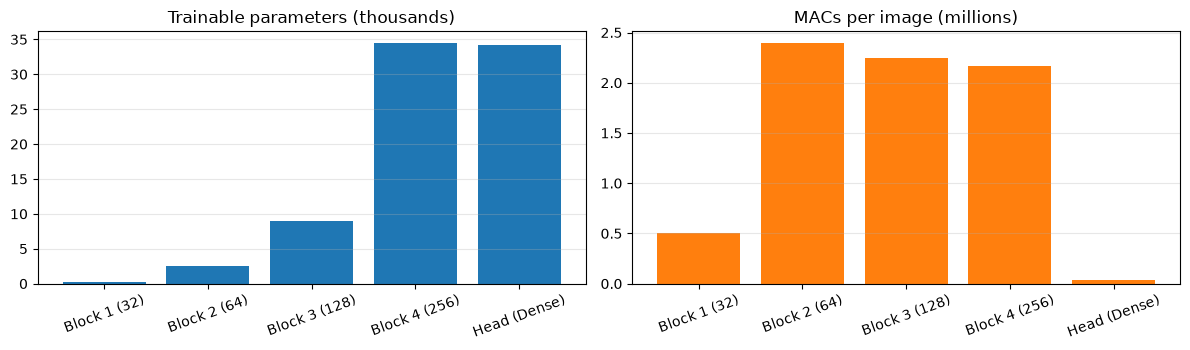

,trainable,macs,share of params,share of MACs
Block 1 (32),187,503808,0.2%,6.9%
Block 2 (64),2464,2392064,3.1%,32.6%
Block 3 (128),9024,2244608,11.2%,30.6%
Block 4 (256),34432,2170880,42.9%,29.6%
Head (Dense),34186,34048,42.6%,0.5%


In [52]:
# Where do the parameters and the computation sit? (per block)
names = ["Block 1 (32)", "Block 2 (64)", "Block 3 (128)", "Block 4 (256)", "Head (Dense)"]
per_block = pd.DataFrame(0, index=names, columns=["trainable", "macs"])
block = -1
for _, r in table.iterrows():
    if r.layer.startswith("SeparableConv2D"):
        block += 1
    per_block.loc[names[block] if r.layer.startswith(("SeparableConv2D", "BatchNorm")) else names[-1]] += [r.trainable, r.macs]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(names, per_block.trainable / 1e3, color="#1f77b4"); ax[0].set_title("Trainable parameters (thousands)")
ax[1].bar(names, per_block.macs / 1e6, color="#ff7f0e");    ax[1].set_title("MACs per image (millions)")
for a in ax:
    a.tick_params(axis="x", rotation=20); a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "model_b_cost_per_block.png", dpi=150); plt.show()

per_block["share of params"] = (per_block.trainable / per_block.trainable.sum()).map("{:.1%}".format)
per_block["share of MACs"] = (per_block.macs / per_block.macs.sum()).map("{:.1%}".format)
per_block

## 4. Design justification

**Depthwise + pointwise.** Depthwise kernels learn spatial patterns per input channel;
pointwise kernels mix channels. With depth multiplier 1, the convolution MAC ratio
relative to standard convolution is `1/Cout + 1/(k*k)`. Arithmetic is reduced, while
one block's spatial/channel interactions are restricted. Accuracy requires training.

**Same widths and head.** Keep Model A's widths, four 2x2 pools and classifier so the
architectural comparison focuses on convolution replacement. GAP avoids flattening
4x4x256 values into an expensive dense layer. Dense(128) fits within the budget;
Dropout(0.5) regularises it.

**Hardware-aware activations.** Hidden ReLU needs a comparison/clamp, without
exponentials, and suits quantized inference. BatchNorm supports training stability;
its inference transform can be folded into the pointwise convolution by supporting
deployment toolchains. Its learned shift removes the need for convolution bias.
Softmax applies exponentials only to 10 outputs. For deployment needing only a class
label, argmax on pre-softmax logits gives the same class without softmax.

**Trade-off.** Model B has 80,293 trainable parameters versus 423,082 for Model A,
and 7,345,408 MACs versus 60,196,096: **87.80% fewer MACs**, an **8.20x MAC ratio**.
This is not a measured speedup: memory traffic, hardware and kernel support affect
latency. Measure disk size, training time and accuracy after training.

The following sections train Model B for at least **20 epochs**, plot learning curves,
evaluate the selected model on the held-out test split, and save measured results
using `results/README.md`. Comparing Adam against SGD and SGD with momentum, and
training Model A with the same protocol, remain separate assignment work.

References: [Keras SeparableConv2D](https://keras.io/api/layers/convolution_layers/separable_convolution2d/)
and [official EuroSAT archive and checksum](https://zenodo.org/records/7711810).

## 5. Train Model B

Train for **20 complete epochs** by default; increase `EPOCHS` below if needed.
Adam at learning rate **0.001** is a starting configuration: its adaptive updates
provide a practical baseline for training this network from scratch. This choice
has not been established as optimal by an optimizer comparison.

Use sparse categorical cross-entropy because labels are integer class indices.
The training split updates weights; validation loss selects the best epoch.
There is no early stopping, so all requested epochs run. The test split is used
only after selection. Running the training cell again starts a fresh model.

The best checkpoint is `results/model_b_full.keras` (optimizer included, already
ignored by Git). Epoch timing includes validation and checkpoint writing; the
reported average excludes the first epoch's initial overhead.

In [53]:
EPOCHS = 20
LEARNING_RATE = 1e-3
OPTIMIZER_NAME = 'Adam'
CHECKPOINT_PATH = RESULTS_DIR / 'model_b_full.keras'


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.started_at = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self.started_at)

In [54]:
if not isinstance(EPOCHS, int) or EPOCHS < 20:
    raise ValueError('Use at least 20 epochs for the assignment.')
tf.keras.utils.set_random_seed(SEED)
model_b = build_model_b()  # Fresh weights for each complete training run.
assert int(sum(np.prod(w.shape) for w in model_b.trainable_weights)) <= PARAMETER_LIMIT
model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

epoch_timer = EpochTimer()
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_PATH), monitor='val_loss', mode='min',
    save_best_only=True, verbose=0,
)
history = model_b.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[checkpoint, epoch_timer], verbose=2,
)
epoch_times = epoch_timer.epoch_times
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
model_b = tf.keras.models.load_model(CHECKPOINT_PATH)
timed_epochs = epoch_times[1:] if len(epoch_times) > 1 else epoch_times
time_per_epoch_s = float(np.mean(timed_epochs))
print(f'Completed {len(history.history["loss"])} epochs.')
print(f'Final training accuracy: {history.history["accuracy"][-1]:.2%}')
print(f'Best epoch by validation loss: {best_epoch}')
print(f'Validation accuracy at selected epoch: {history.history["val_accuracy"][best_epoch - 1]:.2%}')
print(f'Mean time per epoch (first excluded): {time_per_epoch_s:.2f} s')

Epoch 1/20


c:\Users\rashmika\Desktop\CNN-For-Image-Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


591/591 - 28s - 47ms/step - accuracy: 0.6091 - loss: 1.1128 - val_accuracy: 0.4207 - val_loss: 1.7780
Epoch 2/20
591/591 - 24s - 41ms/step - accuracy: 0.7322 - loss: 0.7753 - val_accuracy: 0.7719 - val_loss: 0.6392
Epoch 3/20
591/591 - 24s - 41ms/step - accuracy: 0.7738 - loss: 0.6553 - val_accuracy: 0.7383 - val_loss: 0.7322
Epoch 4/20
591/591 - 24s - 41ms/step - accuracy: 0.8021 - loss: 0.5804 - val_accuracy: 0.7988 - val_loss: 0.5750
Epoch 5/20
591/591 - 24s - 41ms/step - accuracy: 0.8320 - loss: 0.5048 - val_accuracy: 0.8012 - val_loss: 0.6273
Epoch 6/20
591/591 - 24s - 41ms/step - accuracy: 0.8511 - loss: 0.4545 - val_accuracy: 0.8096 - val_loss: 0.6258
Epoch 7/20
591/591 - 24s - 41ms/step - accuracy: 0.8624 - loss: 0.4163 - val_accuracy: 0.8642 - val_loss: 0.3657
Epoch 8/20
591/591 - 24s - 41ms/step - accuracy: 0.8699 - loss: 0.3899 - val_accuracy: 0.8835 - val_loss: 0.3533
Epoch 9/20
591/591 - 25s - 41ms/step - accuracy: 0.8783 - loss: 0.3615 - val_accuracy: 0.8005 - val_loss: 0

## 6. Training and validation curves

The dashed line marks the epoch selected by minimum validation loss. The curves
show all epochs; the model restored for testing comes from the selected epoch.
Training accuracy uses dropout and batch statistics during weight updates;
validation accuracy is measured in inference mode, so their values can differ.

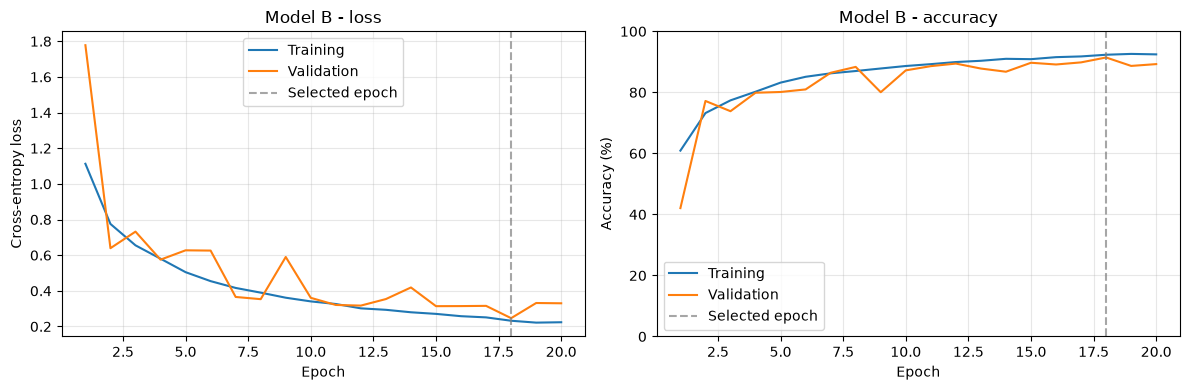

In [55]:
epochs_axis = np.arange(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, history.history['loss'], label='Training')
axes[0].plot(epochs_axis, history.history['val_loss'], label='Validation')
axes[0].set(title='Model B - loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].plot(epochs_axis, np.array(history.history['accuracy']) * 100, label='Training')
axes[1].plot(epochs_axis, np.array(history.history['val_accuracy']) * 100, label='Validation')
axes[1].set(title='Model B - accuracy', xlabel='Epoch', ylabel='Accuracy (%)', ylim=(0, 100))
for axis in axes:
    axis.axvline(best_epoch, color='gray', linestyle='--', alpha=0.7, label='Selected epoch')
    axis.grid(alpha=0.3)
    axis.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'model_b_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Evaluate on the held-out test split

Evaluate the selected model on all **4,050 test images**. Report test accuracy,
loss, macro precision/recall/F1, a per-class report and a confusion matrix.
Predictions and labels are collected together from the unshuffled test dataset.
Confusion-matrix rows are true classes and columns are predictions, in alphabetical
class order. Use validation data, rather than test metrics, to choose future settings.

127/127 - 2s - 16ms/step - accuracy: 0.9217 - loss: 0.2360
Test images: 4,050
Test accuracy: 92.17%
Test loss: 0.2360
Macro precision: 0.9273 | recall: 0.9162 | F1: 0.9179
                      precision    recall  f1-score   support

          AnnualCrop     0.8386    0.9467    0.8894       450
              Forest     0.9630    0.9822    0.9725       450
HerbaceousVegetation     0.8540    0.9356    0.8929       450
             Highway     0.9588    0.8693    0.9119       375
          Industrial     0.9655    0.9707    0.9681       375
             Pasture     0.9568    0.8867    0.9204       300
       PermanentCrop     0.9651    0.6640    0.7867       375
         Residential     0.9696    0.9933    0.9813       450
               River     0.8607    0.9227    0.8906       375
             SeaLake     0.9409    0.9911    0.9654       450

            accuracy                         0.9217      4050
           macro avg     0.9273    0.9162    0.9179      4050
        weighted avg

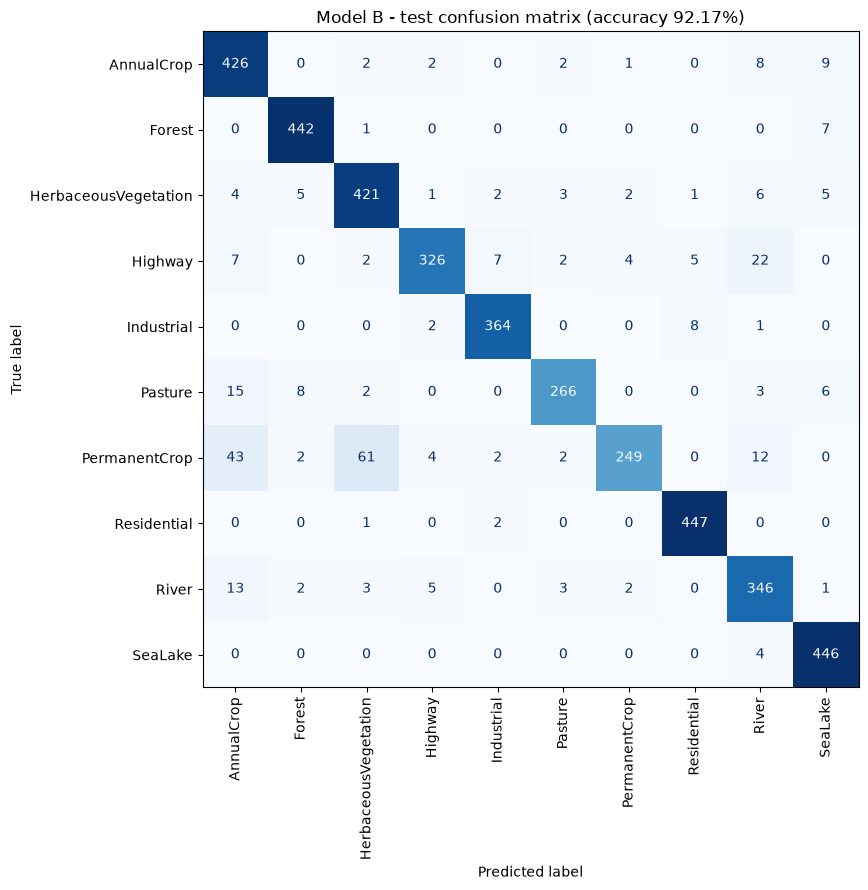

In [56]:
test_metrics = model_b.evaluate(test_ds, return_dict=True, verbose=2)
true_batches, predicted_batches = [], []
for images, labels in test_ds:
    probabilities = model_b(images, training=False).numpy()
    true_batches.append(labels.numpy())
    predicted_batches.append(np.argmax(probabilities, axis=1))
y_true = np.concatenate(true_batches)
y_pred = np.concatenate(predicted_batches)
class_ids = np.arange(NUM_CLASSES)
test_accuracy = float(accuracy_score(y_true, y_pred))
assert np.isclose(test_accuracy, test_metrics['accuracy'], atol=1e-6)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=class_ids, average='macro', zero_division=0,
)
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=class_ids, average=None, zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
print(f'Test images: {len(y_true):,}')
print(f'Test accuracy: {test_accuracy:.2%}')
print(f'Test loss: {test_metrics["loss"]:.4f}')
print(f'Macro precision: {precision_macro:.4f} | recall: {recall_macro:.4f} | F1: {f1_macro:.4f}')
print(classification_report(
    y_true, y_pred, labels=class_ids, target_names=CLASS_NAMES, digits=4, zero_division=0,
))

fig, axis = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(
    ax=axis, cmap='Blues', xticks_rotation=90, values_format='d', colorbar=False,
)
axis.set_title(f'Model B - test confusion matrix (accuracy {test_accuracy:.2%})')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'model_b_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Save the trained model and measured results

Save an **uncompiled copy of the selected model**, without optimizer state, to
`results/model_b.keras`. Its actual file size is reported in KiB/MiB (1024-based,
stored under the repository's `size_kb`/`size_mb` names). Save metrics, per-class
scores, confusion matrix, history and timing to `results/model_b.json`, following
`results/README.md`. These files are created only after training and evaluation.

In [57]:
deploy_model = build_model_b()
deploy_model.set_weights(model_b.get_weights())
model_path = RESULTS_DIR / 'model_b.keras'
deploy_model.save(model_path)
trainable_params = int(sum(np.prod(w.shape) for w in deploy_model.trainable_weights))
assert trainable_params <= PARAMETER_LIMIT
size_bytes = model_path.stat().st_size
results = {
    'model': 'Model B',
    'trainable_params': trainable_params,
    'total_params': int(deploy_model.count_params()),
    'macs': int(MODEL_B_MACS),
    'size_kb': float(size_bytes / 1024),
    'size_mb': float(size_bytes / 1024 ** 2),
    'epochs': len(history.history['loss']),
    'best_epoch': int(best_epoch),
    'selection_metric': 'val_loss',
    'time_per_epoch_s': time_per_epoch_s,
    'epoch_times_s': [float(value) for value in epoch_times],
    'optimizer': OPTIMIZER_NAME,
    'learning_rate': float(LEARNING_RATE),
    'test_loss': float(test_metrics['loss']),
    'test_accuracy': test_accuracy,
    'precision_macro': float(precision_macro),
    'recall_macro': float(recall_macro),
    'f1_macro': float(f1_macro),
    'class_names': list(CLASS_NAMES),
    'per_class': {
        name: {'precision': float(precision[i]), 'recall': float(recall[i]),
               'f1': float(f1[i]), 'support': int(support[i])}
        for i, name in enumerate(CLASS_NAMES)
    },
    'confusion_matrix': cm.tolist(),
    'history': {key: [float(value) for value in history.history[key]]
                for key in ['loss', 'val_loss', 'accuracy', 'val_accuracy']},
}
results_path = RESULTS_DIR / 'model_b.json'
with results_path.open('w', encoding='utf-8') as stream:
    json.dump(results, stream, indent=2, allow_nan=False)
print(f'Saved trained model: {model_path}')
print(f'Saved metrics: {results_path}')
print(f'Test accuracy: {test_accuracy:.2%} | trainable parameters: {trainable_params:,}')
print(f'Model file size: {size_bytes / 1024:.1f} KiB ({size_bytes / 1024 ** 2:.3f} MiB)')

Saved trained model: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\results\model_b.keras
Saved metrics: C:\Users\rashmika\Desktop\CNN-For-Image-Classification\results\model_b.json
Test accuracy: 92.17% | trainable parameters: 80,293
Model file size: 393.5 KiB (0.384 MiB)
